# Step 1: Library Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules for preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier # For Feature Selection

# Models for Classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Display settings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
import zipfile
import os

zip_path = '/content/egypt_education_dataset.csv.zip'
extract_path = '/content/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Step 2: Loading dataset

In [16]:
df = pd.read_csv("egypt_education_dataset.csv")

In [39]:
df.head()

,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Subject_1,Subject_2,Subject_3,Subject_4,Subject_5,Subject_6,Subject_7,Subject_8,Subject_9,Subject_10
0,Allison Lang,18,Year 9,High School,High School,IB,72.236740,85.931149,65.698513,84.163844,78.179414,50.578209,70.071681,80.294509,72.709741,59.080678
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,91.603078,73.186427,64.240239,47.786542,83.138581,66.913702,42.587211,87.997009,89.176862,78.493158
2,Melissa Lee,16,Year 10,Bachelor,PhD,IB,100.000000,83.985923,89.378162,82.446853,86.368818,90.347020,100.000000,83.972296,69.212961,79.206634
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,Thanweya,91.082131,100.000000,78.802220,78.447670,64.606239,82.045421,69.869099,91.122870,95.207752,52.602706
4,Eric Steele,17,Year 11,PhD,Bachelor,IGCSE,74.906144,69.518146,65.284841,56.317028,69.758140,85.810641,63.776955,61.802599,84.951132,68.146467


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student Name    50000 non-null  object 
 1   Student Age     50000 non-null  int64  
 2   Student year    50000 non-null  object 
 3   Father Degree   50000 non-null  object 
 4   Mother Degree   50000 non-null  object 
 5   Education Type  50000 non-null  object 
 6   Subject_1       50000 non-null  float64
 7   Subject_2       50000 non-null  float64
 8   Subject_3       50000 non-null  float64
 9   Subject_4       50000 non-null  float64
 10  Subject_5       50000 non-null  float64
 11  Subject_6       50000 non-null  float64
 12  Subject_7       50000 non-null  float64
 13  Subject_8       50000 non-null  float64
 14  Subject_9       50000 non-null  float64
 15  Subject_10      50000 non-null  float64
dtypes: float64(10), int64(1), object(5)
memory usage: 6.1+ MB


In [7]:
df.describe()

,Student Age,Subject_1,Subject_2,Subject_3,Subject_4,Subject_5,Subject_6,Subject_7,Subject_8,Subject_9,Subject_10
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,16.00368,74.730855,74.697132,74.658231,74.789693,74.610735,74.741407,74.690653,74.734522,74.710284,74.689639
std,1.41582,14.345020,14.367525,14.330384,14.366513,14.326871,14.408353,14.348436,14.373802,14.355054,14.365250
min,14.00000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
25%,15.00000,64.918132,64.786097,64.870431,64.884569,64.752157,64.837589,64.944466,64.985014,64.977238,64.845485
50%,16.00000,75.050027,74.916854,74.959196,75.045955,74.920325,75.083056,74.966657,74.949263,75.033263,74.987325
75%,17.00000,85.145231,85.139383,84.972541,85.268959,84.984459,85.208810,85.071789,85.119971,85.152224,85.087438
max,18.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


In [8]:
df.describe(exclude='number')

,Student Name,Student year,Father Degree,Mother Degree,Education Type
count,50000,50000,39960,39910,50000
unique,40111,4,4,4,3
top,Michael Smith,Year 10,Bachelor,Bachelor,IB
freq,25,12669,10197,10014,16977


# Step 3: Data cleaning

In [9]:
# 1. Remove duplicate rows
initial_shape = df.shape
df = df.drop_duplicates()
print(f"Dropped {initial_shape[0] - df.shape[0]} duplicate rows.")

Dropped 0 duplicate rows.


In [10]:
# 2. Identify missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Missing Values Count ---
Student Name          0
Student Age           0
Student year          0
Father Degree     10040
Mother Degree     10090
Education Type        0
Subject_1             0
Subject_2             0
Subject_3             0
Subject_4             0
Subject_5             0
Subject_6             0
Subject_7             0
Subject_8             0
Subject_9             0
Subject_10            0
dtype: int64


In [37]:
print("Missing values before filling:")
print(df[['Father Degree', 'Mother Degree']].isnull().sum())

df['Father Degree'] = df['Father Degree'].fillna(df['Father Degree'].mode()[0])
df['Mother Degree'] = df['Mother Degree'].fillna(df['Mother Degree'].mode()[0])

print("\nMissing values after filling:")
print(df[['Father Degree', 'Mother Degree']].isnull().sum())

Missing values before filling:
Father Degree    10040
Mother Degree    10090
dtype: int64

Missing values after filling:
Father Degree    0
Mother Degree    0
dtype: int64


In [42]:
subject_cols = [f'Subject_{i}' for i in range(1, 11)]

df['Grade'] = df[subject_cols].mean(axis=1)

df = df.drop(columns=subject_cols)

print(f"Created 'Grade' column. Dropped {len(subject_cols)} subject columns.")


KeyError: "None of [Index(['Subject_1', 'Subject_2', 'Subject_3', 'Subject_4', 'Subject_5',\n       'Subject_6', 'Subject_7', 'Subject_8', 'Subject_9', 'Subject_10'],\n      dtype='object')] are in the [columns]"

In [43]:
df.head()

,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Grade
0,Allison Lang,18,Year 9,High School,High School,IB,71.894448
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,72.512281
2,Melissa Lee,16,Year 10,Bachelor,PhD,IB,86.491867
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,Thanweya,80.378611
4,Eric Steele,17,Year 11,PhD,Bachelor,IGCSE,70.027209


# Step 4: Outliers detection & treatment

In [44]:
def get_outlier_limits(dataframe, column, method='iqr'):
    """Calculates upper and lower limits based on the selected method."""
    if method == 'iqr':
        Q1 = dataframe[column].quantile(0.25)
        Q3 = dataframe[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR
    elif method == 'z-score':
        mean = dataframe[column].mean()
        std = dataframe[column].std()
        lower_limit = mean - 3 * std # 3 Standard Deviations
        upper_limit = mean + 3 * std
    elif method == 'percentile':
        lower_limit = dataframe[column].quantile(0.01) # 1st Percentile
        upper_limit = dataframe[column].quantile(0.99) # 99th Percentile
    else:
        raise ValueError("Method must be 'iqr', 'z-score', or 'percentile'")
    return lower_limit, upper_limit

def treat_outliers(dataframe, column, method='iqr', treatment='cap'):
    """Applies capping or trimming to the specified column."""
    df_treated = dataframe.copy()
    lower_limit, upper_limit = get_outlier_limits(df_treated, column, method)

    if treatment == 'cap':
        df_treated[column] = np.clip(df_treated[column], lower_limit, upper_limit)
    elif treatment == 'trim':
        df_treated = df_treated[(df_treated[column] >= lower_limit) & (df_treated[column] <= upper_limit)]
    else:
        raise ValueError("Treatment must be 'cap' or 'trim'")

    return df_treated

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
sample_col = 'HeartDisease' if 'HeartDisease' in num_cols else num_cols[0]


In [45]:
# ---------------------------------------------------------
# COMPARISON BLOCK: Testing all methods on a single column
# ---------------------------------------------------------
methods = ['iqr', 'z-score', 'percentile']
treatments = ['cap', 'trim']

print(f"--- Comparing Outlier Treatments for column: '{sample_col}' ---")
print(f"Original shape: {df.shape} | Original variance: {df[sample_col].var():.2f}\n")

for method in methods:
    for treatment in treatments:
        test_df = treat_outliers(df, sample_col, method=method, treatment=treatment)
        print(f"Method: {method.upper():<10} | Treatment: {treatment.upper():<4} | New Shape: {test_df.shape} | New Variance: {test_df[sample_col].var():.2f}")

--- Comparing Outlier Treatments for column: 'Student Age' ---
Original shape: (50000, 7) | Original variance: 2.00

Method: IQR        | Treatment: CAP  | New Shape: (50000, 7) | New Variance: 2.00
Method: IQR        | Treatment: TRIM | New Shape: (50000, 7) | New Variance: 2.00
Method: Z-SCORE    | Treatment: CAP  | New Shape: (50000, 7) | New Variance: 2.00
Method: Z-SCORE    | Treatment: TRIM | New Shape: (50000, 7) | New Variance: 2.00
Method: PERCENTILE | Treatment: CAP  | New Shape: (50000, 7) | New Variance: 2.00
Method: PERCENTILE | Treatment: TRIM | New Shape: (50000, 7) | New Variance: 2.00


In [46]:
# ---------------------------------------------------------
# OUTLIER DETECTION SUMMARY: Count, Range, and Post-Capping Range
# (Across ALL numerical columns, excluding Age)
# ---------------------------------------------------------
cols_for_outlier_summary = [col for col in num_cols if col != 'Student Age']

summary_rows = []

for col in cols_for_outlier_summary:
    for method in methods:
        lower_limit, upper_limit = get_outlier_limits(df, col, method=method)

        outliers_mask = (df[col] < lower_limit) | (df[col] > upper_limit)
        n_outliers = outliers_mask.sum()

        if n_outliers > 0:
            outlier_min = df.loc[outliers_mask, col].min()
            outlier_max = df.loc[outliers_mask, col].max()
            outlier_range = f"[{outlier_min:.2f}, {outlier_max:.2f}]"
        else:
            outlier_range = "No outliers"

        # Simulate actual capping to get the REAL resulting range (not just the raw limits)
        capped_col = np.clip(df[col], lower_limit, upper_limit)
        actual_capped_min = capped_col.min()
        actual_capped_max = capped_col.max()
        capped_range = f"[{actual_capped_min:.2f}, {actual_capped_max:.2f}]"

        summary_rows.append({
            "Column": col,
            "Method": method.upper(),
            "Outliers Detected": n_outliers,
            "Original Outlier Range": outlier_range,
            "Range After Capping (Actual)": capped_range
        })

outlier_summary_df = pd.DataFrame(summary_rows)

pd.set_option('display.max_rows', None)
display(outlier_summary_df)

,Column,Method,Outliers Detected,Original Outlier Range,Range After Capping (Actual)
0,Grade,IQR,316,"[56.82, 91.55]","[62.44, 87.04]"
1,Grade,Z-SCORE,124,"[56.82, 91.55]","[61.09, 88.35]"
2,Grade,PERCENTILE,1000,"[56.82, 91.55]","[63.97, 85.05]"


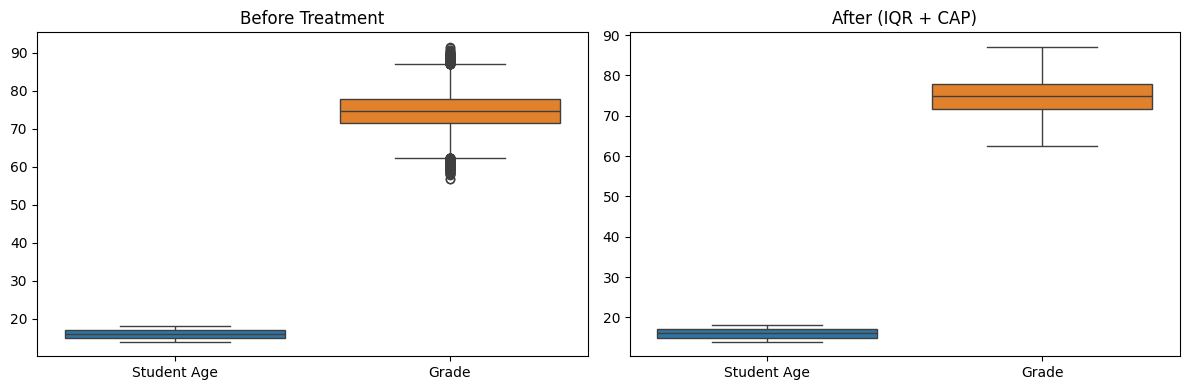


Applied IQR with CAPping to all numerical columns. Final shape: (50000, 7)


In [47]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'iqr'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

df1=df.copy()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df1[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df1 = treat_outliers(df1, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df1[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df1.shape}")

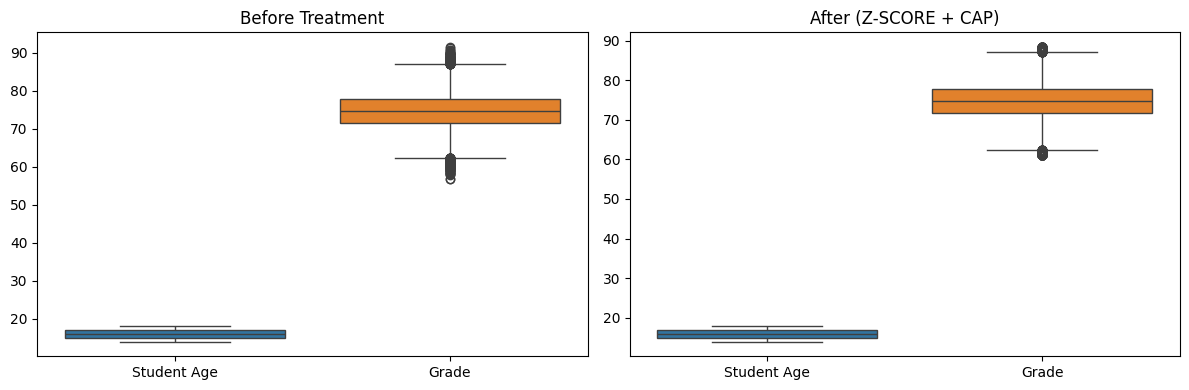


Applied Z-SCORE with CAPping to all numerical columns. Final shape: (50000, 7)


In [48]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'z-score'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

df2=df.copy()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df2[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df2 = treat_outliers(df2, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df2[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df2.shape}")

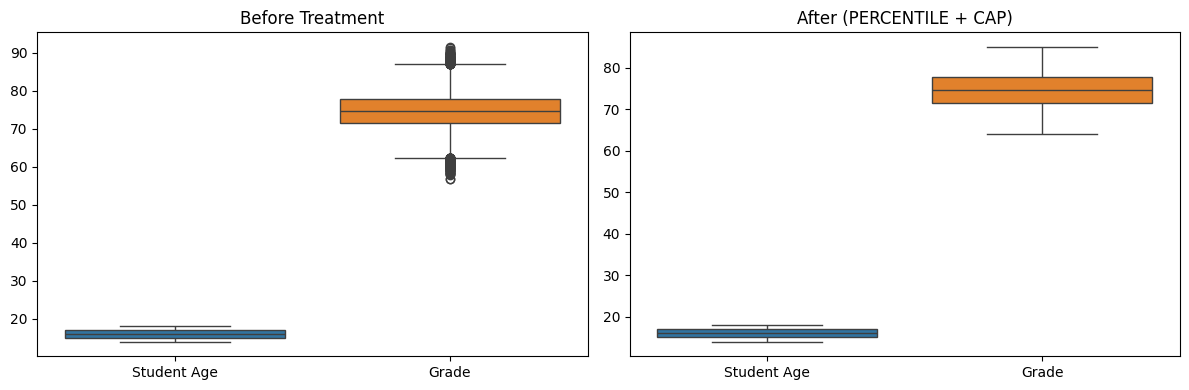


Applied PERCENTILE with CAPping to all numerical columns. Final shape: (50000, 7)


In [49]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'percentile'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

df3=df.copy()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df3[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df3 = treat_outliers(df3, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df3[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df3.shape}")

# Step 5: Feature Engineering

Presequties start

In [50]:
df=df1.copy()

In [67]:
print(df['Student year'].unique())
print(df['Father Degree'].unique())
print(df['Mother Degree'].unique())
print(df['Student Age'].unique())
print(df['Education Type'].unique())

['Year 9' 'Year 10' 'Year 11' 'Year 12']
['High School' 'Bachelor' 'PhD' 'Master']
['High School' 'PhD' 'Bachelor' 'Master']
[18 14 16 17 15]
['IB' 'Thanweya' 'IGCSE']


In [52]:
df['Father Degree'].unique()

array(['High School', 'Bachelor', 'PhD', 'Master'], dtype=object)

In [53]:
df['Mother Degree'].unique()

array(['High School', 'PhD', 'Bachelor', 'Master'], dtype=object)

In [54]:
df['Student Age'].unique()

array([18, 14, 16, 17, 15])

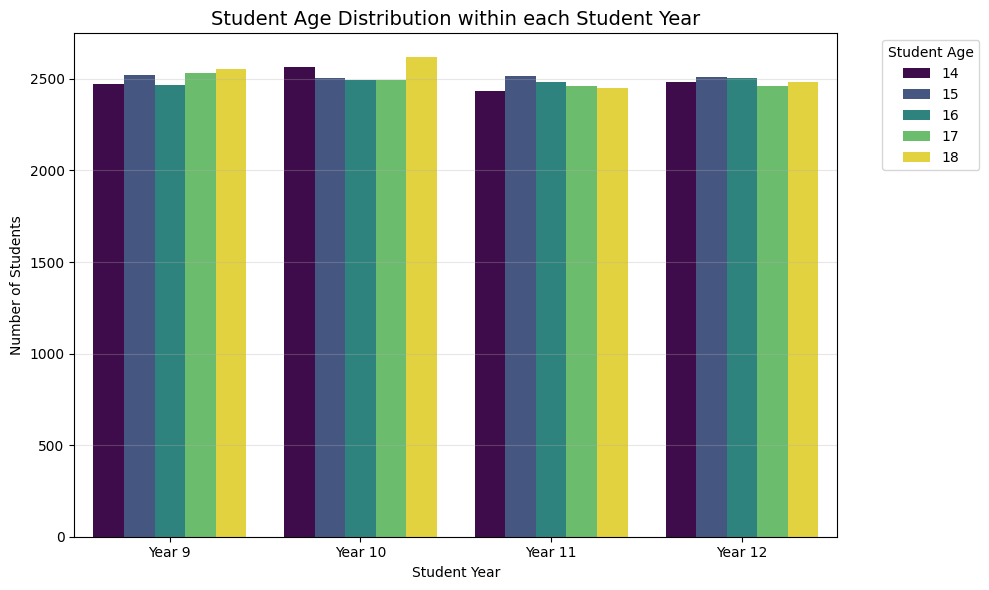

In [61]:
# ---------------------------------------------------------
# Visualization: Student Age Distribution within each Student Year (Grouped Bars)
# ---------------------------------------------------------
year_order = ['Year 9', 'Year 10', 'Year 11', 'Year 12']

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Student year', hue='Student Age', order=year_order, palette='viridis')
plt.title("Student Age Distribution within each Student Year", fontsize=14)
plt.xlabel("Student Year")
plt.ylabel("Number of Students")
plt.legend(title='Student Age', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

presequties end

In [55]:
# ---------------------------------------------------------
# Feature Engineering: Parental Education Features
# ---------------------------------------------------------
degree_order = {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3}

father_edu_level = df['Father Degree'].map(degree_order)
mother_edu_level = df['Mother Degree'].map(degree_order)

df['Max_Parent_Education'] = np.maximum(father_edu_level, mother_edu_level)
df['Both_Parents_Higher_Ed'] = ((father_edu_level >= 1) & (mother_edu_level >= 1)).astype(int)

print("Added 'Max_Parent_Education' and 'Both_Parents_Higher_Ed'.")
df[['Father Degree', 'Mother Degree', 'Max_Parent_Education', 'Both_Parents_Higher_Ed']].head()

Added 'Max_Parent_Education' and 'Both_Parents_Higher_Ed'.


,Father Degree,Mother Degree,Max_Parent_Education,Both_Parents_Higher_Ed
0,High School,High School,0,0
1,Bachelor,PhD,3,1
2,Bachelor,PhD,3,1
3,Bachelor,Bachelor,1,1
4,PhD,Bachelor,3,1


In [56]:
df.head()

,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Grade,Max_Parent_Education,Both_Parents_Higher_Ed
0,Allison Lang,18,Year 9,High School,High School,IB,71.894448,0,0
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,72.512281,3,1
2,Melissa Lee,16,Year 10,Bachelor,PhD,IB,86.491867,3,1
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,Thanweya,80.378611,1,1
4,Eric Steele,17,Year 11,PhD,Bachelor,IGCSE,70.027209,3,1


In [57]:

expected_age = {
    'Year 9': 14, 'Year 10': 15, 'Year 11': 16, 'Year 12': 17
}

df['Expected_Age'] = df['Student year'].map(expected_age)

# Acceptable range: one year below to one year above the expected age
df['Min_Acceptable_Age'] = df['Expected_Age'] - 1
df['Max_Acceptable_Age'] = df['Expected_Age'] + 1

df['Age_Year_Mismatch'] = (
    (df['Student Age'] < df['Min_Acceptable_Age']) |
    (df['Student Age'] > df['Max_Acceptable_Age'])
).astype(int)

# Drop helper columns, keep only the flag
df = df.drop(columns=['Expected_Age', 'Min_Acceptable_Age', 'Max_Acceptable_Age'])

print("Added 'Age_Year_Mismatch'.")
print(f"Mismatched students: {df['Age_Year_Mismatch'].sum()} out of {len(df)}")
df[['Student Age', 'Student year', 'Age_Year_Mismatch']].head()
df.head()

Added 'Age_Year_Mismatch'.
Mismatched students: 22543 out of 50000


,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Grade,Max_Parent_Education,Both_Parents_Higher_Ed,Age_Year_Mismatch
0,Allison Lang,18,Year 9,High School,High School,IB,71.894448,0,0,1
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,72.512281,3,1,0
2,Melissa Lee,16,Year 10,Bachelor,PhD,IB,86.491867,3,1,0
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,Thanweya,80.378611,1,1,0
4,Eric Steele,17,Year 11,PhD,Bachelor,IGCSE,70.027209,3,1,0


# Step 6: Data Encoding

In [62]:
df.head()

,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Grade,Max_Parent_Education,Both_Parents_Higher_Ed,Age_Year_Mismatch
0,Allison Lang,18,Year 9,High School,High School,IB,71.894448,0,0,1
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,72.512281,3,1,0
2,Melissa Lee,16,Year 10,Bachelor,PhD,IB,86.491867,3,1,0
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,Thanweya,80.378611,1,1,0
4,Eric Steele,17,Year 11,PhD,Bachelor,IGCSE,70.027209,3,1,0


In [68]:


#  lABEL encoding
year_order = {'Year 9': 9, 'Year 10': 10, 'Year 11': 11, 'Year 12': 12}
df['Student year'] = df['Student year'].map(year_order)

degree_order = {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3}
df['Father Degree'] = df['Father Degree'].map(degree_order)
df['Mother Degree'] = df['Mother Degree'].map(degree_order)

#  One-hot encoding
df = pd.get_dummies(df, columns=['Education Type'], prefix='EduType')

print("Encoding complete.")
df.head()

Encoding complete.


,Student Name,Student Age,Student year,Father Degree,Mother Degree,Grade,Max_Parent_Education,Both_Parents_Higher_Ed,Age_Year_Mismatch,EduType_IB,EduType_IGCSE,EduType_Thanweya
0,Allison Lang,18,9,0,0,71.894448,0,0,1,True,False,False
1,Jaclyn Mcneil,14,9,1,3,72.512281,3,1,0,True,False,False
2,Melissa Lee,16,10,1,3,86.491867,3,1,0,True,False,False
3,Timothy Maxwell,14,10,1,1,80.378611,1,1,0,False,False,True
4,Eric Steele,17,11,3,1,70.027209,3,1,0,False,True,False


# Step 7: Data Splitting

In [69]:
df = df.drop(columns=['Student Name'])

print("Dropped 'Student Name'. Remaining columns:")
print(df.columns.tolist())

Dropped 'Student Name'. Remaining columns:
['Student Age', 'Student year', 'Father Degree', 'Mother Degree', 'Grade', 'Max_Parent_Education', 'Both_Parents_Higher_Ed', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Student Age             50000 non-null  int64  
 1   Student year            50000 non-null  int64  
 2   Father Degree           50000 non-null  int64  
 3   Mother Degree           50000 non-null  int64  
 4   Grade                   50000 non-null  float64
 5   Max_Parent_Education    50000 non-null  int64  
 6   Both_Parents_Higher_Ed  50000 non-null  int64  
 7   Age_Year_Mismatch       50000 non-null  int64  
 8   EduType_IB              50000 non-null  bool   
 9   EduType_IGCSE           50000 non-null  bool   
 10  EduType_Thanweya        50000 non-null  bool   
dtypes: bool(3), float64(1), int64(7)
memory usage: 3.2 MB


In [71]:
target_column = 'Grade'

In [78]:
eduType_cols = [col for col in df.columns if col.startswith('EduType_')]
df[eduType_cols] = df[eduType_cols].astype(int)

print("Converted Education Type dummy columns to int.")
df[eduType_cols].head()

Converted Education Type dummy columns to int.


,EduType_IB,EduType_IGCSE,EduType_Thanweya
0,1,0,0
1,1,0,0
2,1,0,0
3,0,0,1
4,0,1,0


In [146]:
X = df20.drop(target_column, axis=1)
Y = df20[target_column]

X_Train, X_Test, Y_Train, Y_Test = train_test_split(X, Y, test_size=0.2, random_state=0)
print("Training Size: ", X_Train.shape)
print("Testing Size: ", X_Test.shape)

Training Size:  (40000, 6)
Testing Size:  (10000, 6)


# Step 8: Feature Scaling

In [142]:
print("\nScaling numerical features...")
cols_to_scale = X_Train.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_Train[cols_to_scale] = scaler.fit_transform(X_Train[cols_to_scale])
X_Test[cols_to_scale] = scaler.transform(X_Test[cols_to_scale])

display(X_Train.head())


Scaling numerical features...


,Student year,Max_Parent_Education,Both_Parents_Higher_Ed,Age_Year_Mismatch,EduType_IB,EduType_IGCSE,EduType_Thanweya
20330,0.456205,0.044849,0.748089,-0.904671,-0.715064,1.429248,-0.706616
17532,0.456205,1.134073,0.748089,1.105374,-0.715064,-0.699668,1.415195
45819,0.456205,0.044849,-1.336740,1.105374,1.398477,-0.699668,-0.706616
34807,-1.333185,0.044849,0.748089,1.105374,1.398477,-0.699668,-0.706616
31888,1.350900,1.134073,0.748089,1.105374,-0.715064,1.429248,-0.706616


# Step 9: Feature Selection

In [83]:
# --- A. Filter Method: Correlation Matrix ---
corr_matrix = X_Train.corr()

# Dynamically drop highly correlated redundant features (threshold > 0.85)
threshold = 0.85
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column].abs() > threshold)]

print(f"Highly correlated features dropped: {to_drop}")
X_Train = X_Train.drop(columns=to_drop)
X_Test = X_Test.drop(columns=to_drop)

Highly correlated features dropped: []


In [85]:
# Scikit-Learn modules for preprocessing & ML workflow
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

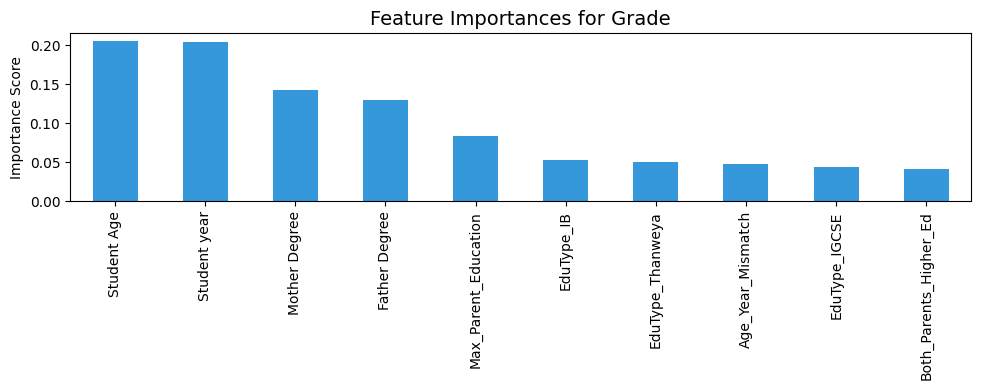

In [88]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_Train, Y_Train)

feature_importances = pd.Series(rf.feature_importances_, index=X_Train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
feature_importances.plot(kind='bar', color='#3498db')
plt.title("Feature Importances for Grade", fontsize=14)
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

In [99]:
df = df.drop(columns=['Father Degree', 'Mother Degree'])

print("Dropped 'Father Degree' and 'Mother Degree'. Remaining columns:")
print(df.columns.tolist())

Dropped 'Father Degree' and 'Mother Degree'. Remaining columns:
['Student Age', 'Student year', 'Grade', 'Max_Parent_Education', 'Both_Parents_Higher_Ed', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


In [140]:
df10=df.copy()
df10 = df10.drop(columns=['Student Age'])

print(df10.columns.tolist())

['Student year', 'Grade', 'Max_Parent_Education', 'Both_Parents_Higher_Ed', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


In [117]:
df20=df10.copy()
df20 = df20.drop(columns=['Max_Parent_Education'])

print(df20.columns.tolist())

['Student year', 'Grade', 'Both_Parents_Higher_Ed', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


In [128]:
df30=df10.copy()
df30 = df30.drop(columns=['Both_Parents_Higher_Ed'])

print(df30.columns.tolist())

['Student year', 'Grade', 'Max_Parent_Education', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


In [134]:
df40=df20.copy()
df40 = df40.drop(columns=['Both_Parents_Higher_Ed'])

print(df40.columns.tolist())

['Student year', 'Grade', 'Age_Year_Mismatch', 'EduType_IB', 'EduType_IGCSE', 'EduType_Thanweya']


# Step 10: Classification Model Comparison

In [147]:
print("\n✅ Data is fully preprocessed! Training final Linear Regression model...")
lr_model = LinearRegression()
lr_model.fit(X_Train, Y_Train)

# Make Predictions
Y_Pred = lr_model.predict(X_Test)

# Evaluate metrics
mae = mean_absolute_error(Y_Test, Y_Pred)
rmse = np.sqrt(mean_squared_error(Y_Test, Y_Pred))
r2 = r2_score(Y_Test, Y_Pred)

print("\n--- Final Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R-squared (R2 Score): {r2:.4f}")


✅ Data is fully preprocessed! Training final Linear Regression model...

--- Final Model Evaluation Metrics ---
Mean Absolute Error (MAE): 3.60
Root Mean Squared Error (RMSE): 4.51
R-squared (R2 Score): -0.0001


In [148]:
tolerance = 5  # predictions within ±5 points count as "correct"
within_tolerance = np.abs(Y_Test - Y_Pred) <= tolerance
accuracy_within_tolerance = within_tolerance.mean() * 100
print(f"Accuracy (within ±{tolerance} points): {accuracy_within_tolerance:.2f}%")

Accuracy (within ±5 points): 73.31%
